# CALOR Y MAYORES EN MADRID

## Priorización: dónde actuar primero y con qué medida

**Diagnóstico:** SHAP en los hexágonos de la isócrona de cada centro, para saber qué lo calienta y qué medida necesita.
**Optimizador:** el modelo simula plantar árboles (+5, +10 y +20 puntos de copa) en cada hexágono candidato y elige los 50 que más enfrían el entorno de los centros más vulnerables.
**Antes y después:** cuántos grados baja la temperatura y cuánto crece la isócrona confortable de cada centro.

## 1. Carga de datos

- importamos las librerías y las funciones del simulador

In [48]:
import sys
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import shap
import osmnx as ox
import networkx as nx
import os


sys.path.append("../scrips")
from config import RUTA_CLEAN
from simulador import cargar_modelo, preparar_hexagonos, calcular_limites, simular_escenarios
from config import RUTA_RAW, RUTA_CLEAN, CRS_PROYECTO
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

- cargamos el modelo y los hexágonos urbanos, con los nulos rellenados igual que en el entrenamiento

In [2]:
modelo, features, mediana_anio_train = cargar_modelo()
hexagonos = preparar_hexagonos(mediana_anio_train)

print("Features:", len(features))
print("Hexágonos urbanos:", hexagonos.shape)
print("Nulos en las features:", hexagonos[features].isnull().sum().sum())

Features: 14
Hexágonos urbanos: (2931, 21)
Nulos en las features: 0


**Observación:** el modelo usa 14 features y hay 2.931 hexágonos urbanos, sin nulos.

- calculamos el aumento de NDVI por punto de copa y el NDVI máximo, los mismos límites que en el simulador

In [3]:
pendiente_ndvi, ndvi_maximo = calcular_limites(hexagonos)

print("Aumento de NDVI por punto de copa:", round(pendiente_ndvi, 4))
print("NDVI máximo:", round(ndvi_maximo, 3))

Aumento de NDVI por punto de copa: 0.0036
NDVI máximo: 0.721


**Observación:** la pendiente (0,0036 de NDVI por punto de copa) y el NDVI máximo (0,721) son los mismos que en el simulador, así que la simulación es coherente con la anterior.

- cargamos la relación centro-hexágono y el índice de riesgo

In [4]:
centros_hexagonos = pd.read_csv(RUTA_CLEAN + "centros_hexagonos.csv")
indice = gpd.read_file(RUTA_CLEAN + "indice_riesgo.gpkg")

print("Pares centro-hexágono:", centros_hexagonos.shape)
print("Centros en el índice:", indice.shape)
print(centros_hexagonos.dtypes)
indice.columns

Pares centro-hexágono: (3083, 2)
Centros en el índice: (439, 24)
codigo    str
h3        str
dtype: object


Index(['codigo', 'nombre', 'tipo_centro', 'plazas', 'titularidad',
       'pct_confort_1.5', 'lst_isocrona', 'copa_isocrona', 'exposicion',
       'vulnerabilidad_tipo', 'anio_edificio', 'vulnerabilidad_edificio',
       'vulnerabilidad', 'nodo', 'dist_agua', 'dist_refugio', 'dist_salud',
       'peligro', 'capacidad', 'capacidad_720', 'riesgo', 'riesgo_720',
       'prioridad', 'geometry'],
      dtype='str')

**Observación:** 3.083 pares centro-hexágono y los 439 centros del índice.

- nos quedamos con los hexágonos candidatos: los que están en la isócrona de algún centro

In [5]:
candidatos = hexagonos[hexagonos["h3"].isin(centros_hexagonos["h3"])].copy()
print("Hexágonos candidatos:", len(candidatos))

Hexágonos candidatos: 1119


**Observación:** 1.119 hexágonos candidatos, los que están en la isócrona de al menos un centro.

## 2. Diagnóstico: qué calienta el entorno de cada centro

**Decisión:** las 14 features se agrupan en 4 palancas sobre las que se puede actuar: vegetación (ndvi, pct_copa, altura_arboles, arboles_ha), suelo desnudo (pct_suelo_desnudo), edificios y cubiertas (pct_edificado, plantas_media, anio_medio, pct_industrial, albedo) y parques (dist_parque_grande). La elevación, la distancia al agua y el viario quedan fuera porque no se pueden cambiar con una intervención. La medida recomendada para cada centro es la palanca que más calienta su isócrona.

- calculamos los valores SHAP en los hexágonos candidatos

In [6]:
explicador = shap.TreeExplainer(modelo)
valores_shap = explicador(candidatos[features])

print("Tamaño de los valores SHAP:", valores_shap.values.shape)
print("Valor base:", round(float(valores_shap.base_values[0]), 2), "°C")

Tamaño de los valores SHAP: (1119, 14)
Valor base: 44.79 °C


**Observación:** valores SHAP de los 1.119 candidatos con las 14 features. El valor base es 44,79 °C, el mismo que en el modelo.

- sumamos los valores SHAP de las features de cada palanca, en cada hexágono

In [7]:
palancas = {
    "vegetacion": ["ndvi", "pct_copa", "altura_arboles", "arboles_ha"],
    "suelo_desnudo": ["pct_suelo_desnudo"],
    "edificios": ["pct_edificado", "plantas_media", "anio_medio", "pct_industrial", "albedo"],
    "parques": ["dist_parque_grande"]
}

shap_hexagonos = pd.DataFrame(valores_shap.values, columns=features)
shap_hexagonos["h3"] = candidatos["h3"].values
for palanca, columnas in palancas.items():
    shap_hexagonos[palanca] = shap_hexagonos[columnas].sum(axis=1)

shap_hexagonos[list(palancas)].describe().round(2)

,vegetacion,suelo_desnudo,edificios,parques
count,1119.00,1119.00,1119.00,1119.00
mean,-0.16,-0.01,-0.62,-0.03
std,1.42,0.03,0.65,0.06
min,-8.90,-0.26,-2.15,-0.14
25%,-0.94,-0.01,-1.09,-0.06
50%,-0.04,-0.00,-0.63,-0.04
75%,0.86,0.00,-0.27,-0.03
max,2.55,0.30,1.97,0.75


**Observación:** la vegetación es la palanca con más rango (de −8,9 a +2,6 °C). Los edificios enfrían en casi todos los hexágonos (mediana −0,63 °C), y el suelo desnudo y los parques mueven menos de 1 °C.

- pasamos de hexágonos a centros: media de cada palanca en los hexágonos de su isócrona

In [8]:
diagnostico = centros_hexagonos.merge(shap_hexagonos[["h3"] + list(palancas)], on="h3", how="left")
diagnostico = diagnostico.groupby("codigo")[list(palancas)].mean().reset_index()

print("Centros con diagnóstico:", diagnostico.shape)
diagnostico.describe().round(2)

Centros con diagnóstico: (439, 5)


,vegetacion,suelo_desnudo,edificios,parques
count,439.00,439.00,439.00,439.00
mean,-0.06,-0.01,-0.64,-0.03
std,0.93,0.02,0.48,0.04
min,-3.38,-0.10,-1.66,-0.10
25%,-0.60,-0.01,-0.96,-0.05
50%,-0.03,-0.01,-0.63,-0.04
75%,0.67,0.00,-0.37,-0.02
max,1.99,0.12,1.32,0.53


**Observación:** la vegetación calienta hasta +2 °C el entorno de algunos centros y enfría hasta −3,4 °C el de otros.

- la medida recomendada es la palanca que más calienta el entorno del centro

In [9]:
diagnostico["medida"] = diagnostico[list(palancas)].idxmax(axis=1)
diagnostico.loc[diagnostico[list(palancas)].max(axis=1) <= 0, "medida"] = "ninguna"

diagnostico["medida"].value_counts()

medida
vegetacion       206
ninguna          152
suelo_desnudo     43
edificios         24
parques           14
Name: count, dtype: int64

**Observación:** la vegetación es la medida recomendada en 206 centros (47 %). En 152 (35 %) ninguna palanca calienta.

- comparamos la medida recomendada con la prioridad del índice de riesgo

In [10]:
diagnostico = diagnostico.merge(indice[["codigo", "nombre", "tipo_centro", "prioridad"]], on="codigo", how="left")
pd.crosstab(diagnostico["prioridad"], diagnostico["medida"])

medida,edificios,ninguna,parques,suelo_desnudo,vegetacion
prioridad,,,,,
alta,8,3,2,2,73
baja,11,126,7,28,48
media,5,23,5,13,85


**Observación:** en 73 de los 88 centros de prioridad alta (83 %), lo que más calienta el entorno es la falta de vegetación. Solo 3 de ellos no tienen ninguna palanca que caliente: su riesgo viene de la falta de servicios o de su vulnerabilidad.

## 3. Beneficio de plantar en cada hexágono candidato

- simulamos las tres fases (+5, +10 y +20 puntos de copa) en los 1.119 candidatos con la función del simulador

In [11]:
candidatos = simular_escenarios(candidatos, modelo, features, pendiente_ndvi, ndvi_maximo)

columnas_bajada = ["bajada_bajo", "bajada_moderado", "bajada_ambicioso"]
candidatos[["lst_actual"] + columnas_bajada].describe().round(2)

,lst_actual,bajada_bajo,bajada_moderado,bajada_ambicioso
count,1119.00,1119.00,1119.00,1119.00
mean,43.87,0.34,0.62,1.23
std,1.52,0.21,0.25,0.34
min,35.81,-0.07,0.00,-0.03
25%,42.91,0.22,0.49,1.03
50%,43.87,0.30,0.58,1.19
75%,44.88,0.42,0.71,1.39
max,49.05,2.07,2.76,3.44


**Observación:** plantar enfría de media 0,34, 0,62 y 1,23 °C en las tres fases, con máximos de 2,1, 2,8 y 3,4 °C.

In [12]:
(candidatos[columnas_bajada] < 0).sum()

bajada_bajo         1
bajada_moderado     0
bajada_ambicioso    1
dtype: int64

**Observación:** solo 2 de los 1.119 hexágonos dan una bajada negativa: uno en la fase baja y otro en la ambiciosa, de −0,07 y −0,03 °C. Es un efecto de los escalones del Gradient Boosting, mucho menor que el error del modelo (1 °C).

**Decisión:** las bajadas negativas se dejan en 0, porque en esos hexágonos plantar no aporta beneficio según el modelo.

In [13]:
for columna in columnas_bajada:
    candidatos[columna] = candidatos[columna].clip(lower=0)

print("Bajadas negativas restantes:", (candidatos[columnas_bajada] < 0).sum().sum())

Bajadas negativas restantes: 0


**Observación:** ya no quedan bajadas negativas.

- contamos los hexágonos que casi no mejoran (menos de 0,1 °C) en cada fase

In [14]:
for columna in columnas_bajada:
    n_poco = (candidatos[columna] < 0.1).sum()
    print(f"{columna}: {n_poco} hexágonos mejoran menos de 0,1 °C ({n_poco / len(candidatos) * 100:.0f} %)")

bajada_bajo: 52 hexágonos mejoran menos de 0,1 °C (5 %)
bajada_moderado: 6 hexágonos mejoran menos de 0,1 °C (1 %)
bajada_ambicioso: 4 hexágonos mejoran menos de 0,1 °C (0 %)


**Observación:** en la fase baja, 52 hexágonos (5 %) apenas mejoran; desde la fase moderada, casi todos se benefician.

- relación entre la vegetación actual del hexágono y lo que enfría plantar (fase ambiciosa, +20)

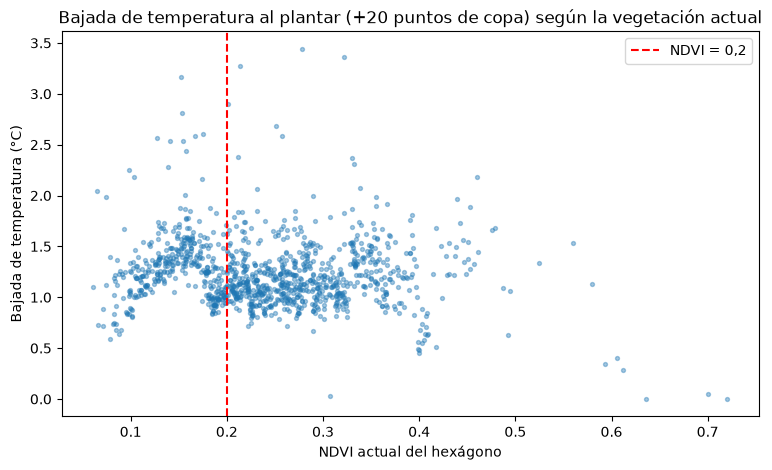

In [15]:
plt.figure(figsize=(9, 5))
plt.scatter(candidatos["ndvi"], candidatos["bajada_ambicioso"], s=8, alpha=0.4)
plt.axvline(0.2, color="red", linestyle="--", label="NDVI = 0,2")
plt.title("Bajada de temperatura al plantar (+20 puntos de copa) según la vegetación actual")
plt.xlabel("NDVI actual del hexágono")
plt.ylabel("Bajada de temperatura (°C)")
plt.legend()
plt.show()

**Observación:** con +20 puntos de copa, el NDVI sube 0,072, y los hexágonos que hoy están entre 0,13 y 0,2 cruzan el umbral al plantar. Por eso son los que más se enfrían (de 1,3 a 1,8 °C), más que los que ya estaban justo por encima de 0,2 (en torno a 1 °C). Por encima de 0,4 de NDVI, la bajada es menor: esos hexágonos ya tienen mucha vegetación y queda poco margen. Es la forma no lineal de la H2 vista en la simulación.

## 4. Optimizador: dónde plantar primero

**Decisión:** el valor de cada hexágono es la bajada de temperatura en la fase moderada (+10) multiplicada por la suma del riesgo de los centros que lo tienen en su isócrona. Se usa el riesgo y no solo el peso (exposición × vulnerabilidad), porque con el peso el optimizador elegía zonas con muchos centros juntos aunque no fueran calientes ni estuvieran mal protegidas, y menos de la mitad de los centros de prioridad alta se beneficiaban.

- calculamos el riesgo de cada hexágono y el número de centros que lo comparten

In [16]:
riesgo_hexagonos = centros_hexagonos.merge(indice[["codigo", "riesgo"]], on="codigo", how="left")
riesgo_hexagonos = riesgo_hexagonos.groupby("h3").agg(
    riesgo_hexagono=("riesgo", "sum"),
    n_centros=("codigo", "size")
).reset_index()

candidatos = candidatos.merge(riesgo_hexagonos, on="h3", how="left")
candidatos[["riesgo_hexagono", "n_centros"]].describe().round(3)

,riesgo_hexagono,n_centros
count,1119.000,1119.000
mean,0.227,2.755
std,0.238,1.718
min,0.000,1.000
25%,0.046,1.000
50%,0.155,2.000
75%,0.334,4.000
max,1.520,12.000


**Observación:** el riesgo sumado va de 0 a 1,52. La mitad de los hexágonos están en la isócrona de 1 o 2 centros, y el máximo lo comparten 12.

- valor de cada hexágono: bajada en la fase moderada × riesgo del hexágono

In [17]:
candidatos["valor"] = candidatos["bajada_moderado"] * candidatos["riesgo_hexagono"]
candidatos["valor"].describe().round(3)

count    1119.000
mean        0.145
std         0.173
min         0.000
25%         0.024
50%         0.087
75%         0.207
max         1.591
Name: valor, dtype: float64

**Observación:** el valor es muy desigual (mediana 0,09, máximo 1,59). Pocos hexágonos concentran el beneficio.

- elegimos los 50 hexágonos de mayor valor

In [18]:
PRESUPUESTO = 50
seleccion = candidatos.nlargest(PRESUPUESTO, "valor")

centros_alcanzados = centros_hexagonos[centros_hexagonos["h3"].isin(seleccion["h3"])]["codigo"].unique()
print("Hexágonos elegidos:", len(seleccion))
print("Centros con al menos un hexágono elegido en su isócrona:", len(centros_alcanzados))
print(indice[indice["codigo"].isin(centros_alcanzados)]["prioridad"].value_counts())

seleccion[["h3", "lst_actual", "bajada_moderado", "n_centros", "riesgo_hexagono", "valor"]].head(10).round(3)

Hexágonos elegidos: 50
Centros con al menos un hexágono elegido en su isócrona: 104
prioridad
alta     53
media    32
baja     19
Name: count, dtype: int64


,h3,lst_actual,bajada_moderado,n_centros,riesgo_hexagono,valor
613,89390ca0053ffff,48.528,2.110,4,0.754,1.591
360,89390cba96bffff,42.665,0.968,5,1.251,1.211
728,89390cb8d37ffff,47.405,2.765,2,0.425,1.175
1012,89390cb1b93ffff,43.582,0.879,8,1.329,1.167
943,89390cb2b7bffff,46.914,1.546,1,0.661,1.021
404,89390ca352fffff,44.731,0.663,5,1.380,0.916
177,89390ca352bffff,44.956,0.815,4,1.105,0.900
567,89390cb0d2fffff,46.785,1.876,2,0.432,0.811
608,89390cba967ffff,45.572,0.529,7,1.520,0.804
945,89390ca36afffff,45.107,0.878,6,0.912,0.801


**Observación:** los 50 hexágonos elegidos alcanzan a 104 centros, 53 de ellos de prioridad alta (el 60 % de los 88).

- curva de 10 a 200 hexágonos: valor acumulado del optimizador frente a la media de 100 selecciones al azar

In [19]:
candidatos_ordenados = candidatos.sort_values("valor", ascending=False)
tamanos = list(range(10, 201, 10))

valor_optimizador = []
valor_azar = []
for n in tamanos:
    valor_optimizador.append(candidatos_ordenados["valor"].head(n).sum())

    sumas_aleatorias = []
    for semilla in range(100):
        sumas_aleatorias.append(candidatos["valor"].sample(n, random_state=semilla).sum())
    valor_azar.append(np.mean(sumas_aleatorias))

curva = pd.DataFrame({"hexagonos": tamanos, "optimizador": valor_optimizador, "azar": valor_azar})
curva["veces_mejor"] = curva["optimizador"] / curva["azar"]
curva.round(2)

,hexagonos,optimizador,azar,veces_mejor
0,10,10.40,1.40,7.44
1,20,18.01,2.76,6.51
2,30,24.38,4.32,5.64
3,40,30.23,5.78,5.23
4,50,35.28,7.28,4.85
5,60,39.99,8.76,4.57
6,70,44.37,10.35,4.29
7,80,48.52,11.82,4.10
8,90,52.51,13.22,3.97
9,100,56.34,14.64,3.85


**Observación:** el optimizador siempre supera al azar, pero su ventaja se reduce al elegir más hexágonos: de 7,4 veces con 10 a 3,0 veces con 200, porque los primeros elegidos son los de más valor.

- gráfico de la curva

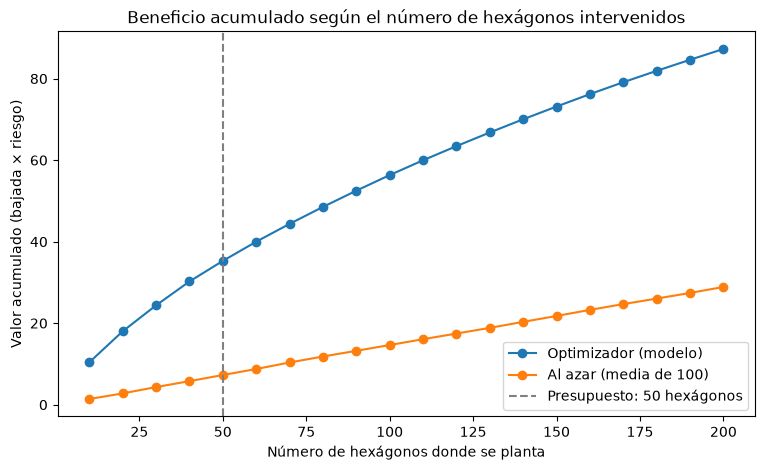

In [20]:
plt.figure(figsize=(9, 5))
plt.plot(curva["hexagonos"], curva["optimizador"], marker="o", label="Optimizador (modelo)")
plt.plot(curva["hexagonos"], curva["azar"], marker="o", label="Al azar (media de 100)")
plt.axvline(PRESUPUESTO, color="grey", linestyle="--", label="Presupuesto: 50 hexágonos")
plt.title("Beneficio acumulado según el número de hexágonos intervenidos")
plt.xlabel("Número de hexágonos donde se planta")
plt.ylabel("Valor acumulado (bajada × riesgo)")
plt.legend()
plt.show()

**Observación:** con 50 hexágonos, el optimizador consigue 4,8 veces más beneficio que el azar, y con 10 hexágonos, 7,4 veces.

## 5. Antes y después: cuánto baja la temperatura del entorno de cada centro

**Plan realista:** se planta solo en los 50 hexágonos elegidos; el resto de hexágonos no cambia. **Potencial máximo:** se planta en los 1.119 hexágonos candidatos, solo como referencia.

- marcamos los hexágonos elegidos y calculamos su bajada en el plan (0 en los no elegidos)

In [21]:
candidatos["elegido"] = candidatos["h3"].isin(seleccion["h3"])

columnas_plan = ["plan_bajo", "plan_moderado", "plan_ambicioso"]
for columna_bajada, columna_plan in zip(columnas_bajada, columnas_plan):
    candidatos[columna_plan] = candidatos[columna_bajada].where(candidatos["elegido"], 0)

print("Hexágonos elegidos:", candidatos["elegido"].sum())
candidatos.loc[candidatos["elegido"], columnas_plan].describe().round(2)

Hexágonos elegidos: 50


,plan_bajo,plan_moderado,plan_ambicioso
count,50.00,50.00,50.00
mean,0.70,1.02,1.75
std,0.47,0.56,0.65
min,0.16,0.45,0.94
25%,0.37,0.64,1.30
50%,0.52,0.81,1.44
75%,1.04,1.25,2.20
max,2.07,2.76,3.36


**Observación:** en los 50 hexágonos donde se planta, la temperatura baja de media 0,70, 1,02 y 1,75 °C, con un máximo de 3,4 °C.

- para cada centro, bajada media de los hexágonos de su isócrona y temperatura después de cada fase

In [22]:
antes_despues = centros_hexagonos.merge(candidatos[["h3"] + columnas_plan + columnas_bajada], on="h3", how="left")
antes_despues = antes_despues.groupby("codigo")[columnas_plan + columnas_bajada].mean().reset_index()
antes_despues = antes_despues.merge(indice[["codigo", "nombre", "tipo_centro", "prioridad", "lst_isocrona"]], on="codigo", how="left")

for columna_plan in columnas_plan:
    antes_despues[columna_plan.replace("plan", "lst_despues")] = antes_despues["lst_isocrona"] - antes_despues[columna_plan]

print(antes_despues.shape)

(439, 14)


**Observación:** tabla de antes y después de los 439 centros, con la bajada y la temperatura de su entorno en cada fase.

- resumen del plan realista en cada fase: todos los centros que mejoran y solo los de prioridad alta

In [23]:
resumen = []
for columna_plan in columnas_plan:
    mejoran = antes_despues[antes_despues[columna_plan] > 0]
    alta = mejoran[mejoran["prioridad"] == "alta"]
    resumen.append({
        "fase": columna_plan,
        "centros_que_mejoran": len(mejoran),
        "bajada_media": mejoran[columna_plan].mean(),
        "bajada_maxima": mejoran[columna_plan].max(),
        "alta_que_mejoran": len(alta),
        "bajada_media_alta": alta[columna_plan].mean()
    })

pd.DataFrame(resumen).round(2)

,fase,centros_que_mejoran,bajada_media,bajada_maxima,alta_que_mejoran,bajada_media_alta
0,plan_bajo,104,0.20,0.90,53,0.24
1,plan_moderado,104,0.29,1.24,53,0.36
2,plan_ambicioso,104,0.52,1.96,53,0.64


**Observación:** el plan beneficia a 104 centros, 53 de prioridad alta. Su isócrona baja de media 0,20, 0,29 y 0,52 °C, y 0,24, 0,36 y 0,64 °C en los de prioridad alta, con un máximo de casi 2 °C.

- los 10 centros que más mejoran en la fase moderada

In [24]:
columnas_ver = ["nombre", "tipo_centro", "prioridad", "lst_isocrona", "lst_despues_moderado"] + columnas_plan
antes_despues.nlargest(10, "plan_moderado")[columnas_ver].round(2)

,nombre,tipo_centro,prioridad,lst_isocrona,lst_despues_moderado,plan_bajo,plan_moderado,plan_ambicioso
48,"DOCTOR GONZALEZ BUENO, RESIDENCIA DE PERSONAS ...",residencia,alta,47.18,45.94,0.90,1.24,1.96
364,RESIDENCIA DE MAYORES CASABLANCA VILLAVERDE,residencia,alta,47.36,46.25,0.76,1.11,1.63
373,CENTRO DE DIA CASABLANCA VILLAVERDE,centro de día,media,47.36,46.25,0.76,1.11,1.63
46,"PLATA Y CASTAÑAR, RESIDENCIA DE PERSONAS MAYORES",residencia,alta,46.83,46.02,0.50,0.81,1.67
47,"PLATA Y CASTAÑAR, CENTRO DE DIA",centro de día,alta,46.83,46.02,0.50,0.81,1.67
408,RESIDENCIA DE PERSONAS MAYORES AMAVIR LA GAVIA,residencia,alta,46.94,46.20,0.54,0.74,0.93
412,RESIDENCIA DE PERSONAS MAYORES CASABLANCA VALL...,residencia,alta,48.16,47.46,0.61,0.70,1.28
413,CENTRO DE DIA CASABLANCA VALLECAS,centro de día,baja,48.16,47.46,0.61,0.70,1.28
437,RESIDENCIA DE PERSONAS MAYORES CASABLANCA VICÁ...,residencia,alta,45.95,45.41,0.45,0.54,0.85
438,CENTRO DE DÍA CASABLANCA VICÁLVARO,centro de día,media,45.95,45.41,0.45,0.54,0.85


**Observación:** el centro que más mejora es Doctor González Bueno, el de mayor riesgo de Madrid: su entorno baja 1,24 °C en la fase moderada y 1,96 °C en la ambiciosa. Le siguen los dos centros de Casablanca Villaverde y los de Plata y Castañar.

- potencial máximo: bajada media de la isócrona si se plantara en los 1.119 hexágonos (solo como referencia)

In [25]:
antes_despues[columnas_bajada].describe().round(2)

,bajada_bajo,bajada_moderado,bajada_ambicioso
count,439.00,439.00,439.00
mean,0.34,0.62,1.23
std,0.12,0.14,0.19
min,0.11,0.31,0.79
25%,0.28,0.54,1.12
50%,0.32,0.59,1.20
75%,0.37,0.65,1.30
max,1.06,1.42,2.29


**Observación:** plantando en los 1.119 hexágonos, el entorno de los 439 centros bajaría de media 0,34, 0,62 y 1,23 °C.

## 6. Isócronas confortables después de intervenir

**Decisión:** se recalcula la isócrona confortable (α = 1,5) solo de los centros que tienen algún hexágono elegido, en las tres fases. A los tramos de calle de los hexágonos elegidos se les resta la bajada de temperatura de cada fase; el resto de tramos no cambia. El calor se escala con los mismos percentiles que en las isócronas (5 y 95), para que el antes y el después sean comparables.

- constantes de las isócronas, las mismas que en isocronas.ipynb

In [26]:
VELOCIDAD = 0.8
MINUTOS = 15
DISTANCIA_MAXIMA = VELOCIDAD * MINUTOS * 60
MARGEN_CALLE = 25
ALFA = 1.5
RADIO_SALIDA = 100

lst_p5 = hexagonos["lst"].quantile(0.05)
lst_p95 = hexagonos["lst"].quantile(0.95)
print("Distancia máxima:", DISTANCIA_MAXIMA, "m")
print("Percentil 5:", round(lst_p5, 2), "°C - percentil 95:", round(lst_p95, 2), "°C")

Distancia máxima: 720.0 m
Percentil 5: 41.09 °C - percentil 95: 50.46 °C


**Observación:** se usan los mismos valores que en las isócronas: 720 m y los percentiles 41,09 y 50,46 °C para escalar el calor.

- cargamos la red peatonal y la pasamos a metros

In [27]:
red = ox.load_graphml(RUTA_RAW + "osm/walk_graph_madrid.graphml")
red = ox.project_graph(red, to_crs=CRS_PROYECTO)
nodos, tramos = ox.graph_to_gdfs(red)
print("Nodos:", len(nodos), "- tramos:", len(tramos))

Nodos: 220894 - tramos: 668278


**Observación:** la misma red que en las isócronas: 220.894 cruces y 668.278 tramos.

- asignamos a cada tramo la temperatura y el código del hexágono en el que está su punto medio

In [28]:
hexagonos_todos = gpd.read_file(RUTA_CLEAN + "hexagonos_h3.gpkg")
puntos_medios = gpd.GeoDataFrame(geometry=tramos.geometry.interpolate(0.5, normalized=True), crs=CRS_PROYECTO)
puntos_medios = gpd.sjoin_nearest(puntos_medios, hexagonos_todos[["h3", "lst", "geometry"]], how="left")
puntos_medios = puntos_medios[~puntos_medios.index.duplicated()]

tramos["lst"] = puntos_medios["lst"]
tramos["h3"] = puntos_medios["h3"]
print("Tramos sin hexágono:", tramos["h3"].isnull().sum())

Tramos sin hexágono: 0


**Observación:** todos los tramos tienen hexágono.

- bajada de temperatura de cada tramo en cada fase (0 si su hexágono no es de los elegidos)

In [29]:
bajadas_plan = candidatos.set_index("h3")[columnas_plan]
for columna_plan in columnas_plan:
    tramos[columna_plan] = tramos["h3"].map(bajadas_plan[columna_plan]).fillna(0)

print("Tramos en hexágonos elegidos:", (tramos["plan_moderado"] > 0).sum())

Tramos en hexágonos elegidos: 11740


**Observación:** 11.740 tramos de calle (el 1,8 % de la red) están en los hexágonos elegidos.

- calor (0 a 1) y coste de cada tramo hoy y en cada fase, y los añadimos a la red

In [30]:
fases = ["hoy", "bajo", "moderado", "ambicioso"]
for fase in fases:
    if fase == "hoy":
        lst_fase = tramos["lst"]
    else:
        lst_fase = tramos["lst"] - tramos[f"plan_{fase}"]
    calor = ((lst_fase - lst_p5) / (lst_p95 - lst_p5)).clip(0, 1)
    tramos[f"coste_{fase}"] = tramos["length"] * (1 + (ALFA - 1) * calor)
    nx.set_edge_attributes(red, tramos[f"coste_{fase}"].to_dict(), f"coste_{fase}")

tramos[[f"coste_{fase}" for fase in fases]].describe().round(1)

,coste_hoy,coste_bajo,coste_moderado,coste_ambicioso
count,668278.0,668278.0,668278.0,668278.0
mean,54.4,54.3,54.3,54.3
std,88.5,88.5,88.5,88.5
min,0.0,0.0,0.0,0.0
25%,11.8,11.8,11.8,11.8
50%,27.5,27.5,27.5,27.4
75%,66.7,66.6,66.6,66.6
max,7654.5,7654.5,7654.5,7654.5


**Observación:** el coste medio de toda la red apenas cambia (de 54,4 a 54,3), porque solo se interviene en una parte muy pequeña de la ciudad.

- recalculamos las isócronas confortables de los 104 centros que mejoran, hoy y en las tres fases

- funciones para calcular la isócrona desde el nodo puerta de cada centro (las mismas de isocronas.ipynb).

In [31]:
def nodos_de_salida(punto):
    """Devuelve los cruces a menos de RADIO_SALIDA m del centro; si no hay ninguno, el más cercano."""
    posiciones = nodos.sindex.query(punto.buffer(RADIO_SALIDA), predicate="intersects")
    if len(posiciones) == 0:
        return [ox.distance.nearest_nodes(red, X=punto.x, Y=punto.y)]
    return list(nodos.index[posiciones])


def isocrona_desde_puerta(punto, peso):
    """Polígono de las calles alcanzadas desde la puerta del centro, eligiendo la mejor salida a menos de RADIO_SALIDA m."""
    salidas = nodos_de_salida(punto)
    red.add_node("puerta")
    for nodo in salidas:
        distancia = punto.distance(nodos.loc[nodo, "geometry"])
        red.add_edge("puerta", nodo, **{peso: distancia})

    alcanzados = nx.single_source_dijkstra_path_length(red, "puerta", cutoff=DISTANCIA_MAXIMA, weight=peso)
    red.remove_node("puerta")

    tramos_alcanzados = tramos[
        tramos.index.get_level_values("u").isin(alcanzados) &
        tramos.index.get_level_values("v").isin(alcanzados)
    ]
    return tramos_alcanzados.buffer(MARGEN_CALLE).union_all()

- recalculamos la isócrona confortable de los centros que mejoran, hoy y en cada fase

In [32]:
isocronas_normales = gpd.read_file(RUTA_CLEAN + "isocronas_normales.gpkg")
codigos_mejoran = antes_despues.loc[antes_despues["plan_moderado"] > 0, "codigo"]

confort = indice[indice["codigo"].isin(codigos_mejoran)][["codigo", "nombre", "tipo_centro", "prioridad", "nodo", "pct_confort_1.5", "geometry"]]
confort = confort.merge(isocronas_normales[["codigo", "area_km2"]], on="codigo", how="left").reset_index(drop=True)
print("Centros a recalcular:", len(confort))

poligonos_fases = {}
for fase in fases:
    poligonos = []
    areas = []
    for punto in confort.geometry:
        poligono = isocrona_desde_puerta(punto, f"coste_{fase}")
        poligonos.append(poligono)
        areas.append(poligono.area / 1_000_000)
    poligonos_fases[fase] = poligonos
    confort[f"pct_confort_{fase}"] = (np.round(areas, 3) / confort["area_km2"] * 100).round(1)
    print(f"{fase}: terminado")

Centros a recalcular: 104
hoy: terminado
bajo: terminado
moderado: terminado
ambicioso: terminado


**Observación:** se recalculan las isócronas confortables de los 104 centros, hoy y en las tres fases.

- comprobamos que el % de confort de hoy coincide con el del índice

In [33]:
print("Diferencia máxima:", (confort["pct_confort_hoy"] - confort["pct_confort_1.5"]).abs().max())

Diferencia máxima: 0.0


**Observación:** el % de confort de hoy coincide exactamente con el del índice (diferencia de 0,0), así que la mejora de las fases se debe solo a los árboles.

- puntos de confort que gana cada centro en cada fase

In [34]:
for fase in ["bajo", "moderado", "ambicioso"]:
    confort[f"gana_{fase}"] = confort[f"pct_confort_{fase}"] - confort["pct_confort_hoy"]

columnas_gana = ["gana_bajo", "gana_moderado", "gana_ambicioso"]
print("Todos los centros que mejoran:")
print(confort[columnas_gana].describe().round(1))
print("\nSolo prioridad alta:")
print(confort.loc[confort["prioridad"] == "alta", columnas_gana].describe().round(1))

Todos los centros que mejoran:
       gana_bajo  gana_moderado  gana_ambicioso
count      104.0          104.0           104.0
mean         0.7            1.1             2.2
std          1.0            1.4             2.4
min          0.0            0.0             0.0
25%          0.0            0.0             0.5
50%          0.2            0.4             1.3
75%          1.0            1.5             3.5
max          4.6            7.0             8.5

Solo prioridad alta:
       gana_bajo  gana_moderado  gana_ambicioso
count       53.0           53.0            53.0
mean         0.8            1.4             2.9
std          1.0            1.5             2.5
min          0.0            0.0             0.0
25%          0.0            0.2             1.0
50%          0.3            0.8             2.2
75%          1.3            2.2             4.4
max          4.6            7.0             8.5


**Observación:** los centros ganan de media 0,7, 1,1 y 2,2 puntos de confort, y los de prioridad alta, 0,8, 1,4 y 2,9. Los máximos son 7 puntos en la fase moderada y 8,5 en la ambiciosa.

- los 10 centros que más confort ganan en la fase moderada

In [35]:
confort.nlargest(10, "gana_moderado")[["nombre", "tipo_centro", "prioridad", "pct_confort_hoy",
                                       "pct_confort_bajo", "pct_confort_moderado", "pct_confort_ambicioso"]]

,nombre,tipo_centro,prioridad,pct_confort_hoy,pct_confort_bajo,pct_confort_moderado,pct_confort_ambicioso
79,RESIDENCIA DE MAYORES CASABLANCA VILLAVERDE,residencia,alta,51.1,55.7,58.1,59.3
82,CENTRO DE DIA CASABLANCA VILLAVERDE,centro de día,media,51.1,55.7,58.1,59.3
6,"FAUSTA ELORZ, RESIDENCIA DE PERSONAS MAYORES",residencia,alta,75.7,77.8,80.1,81.6
13,"ALONSO HEREDIA, CENTRO DE MAYORES",centro de mayores,alta,73.8,76.1,77.8,79.2
45,"CENTRO ALZHEIMER FUNDACIÓN REINA SOFÍA, RESIDE...",residencia,alta,69.1,71.8,72.7,73.5
46,"CENTRO ALZHEIMER FUNDACIÓN REINA SOFÍA, CENTRO...",centro de día,media,69.1,71.8,72.7,73.5
47,"BALLESOL OLAVIDE, RESIDENCIA DE PERSONAS MAYORES",residencia,alta,76.5,78.4,80.1,82.9
8,"PLATA Y CASTAÑAR, RESIDENCIA DE PERSONAS MAYORES",residencia,alta,55.8,57.7,59.1,63.4
9,"PLATA Y CASTAÑAR, CENTRO DE DIA",centro de día,alta,55.8,57.7,59.1,63.4
101,RESIDENCIA DE PERSONAS MAYORES CASABLANCA VICÁ...,residencia,alta,58.0,61.3,61.3,66.5


**Observación:** la Residencia Casablanca Villaverde es la que más gana: pasa del 51,1 % al 59,3 % de confort.

- guardamos las isócronas confortables de cada fase para los mapas y la app

In [36]:
tablas_fases = []
for fase in fases:
    tabla_fase = gpd.GeoDataFrame(confort[["codigo", "nombre", "prioridad"]].copy(),
                                  geometry=poligonos_fases[fase], crs=CRS_PROYECTO)
    tabla_fase["fase"] = fase
    tabla_fase["pct_confort"] = confort[f"pct_confort_{fase}"]
    tablas_fases.append(tabla_fase)

isocronas_plan = pd.concat(tablas_fases, ignore_index=True)
isocronas_plan.to_file(RUTA_CLEAN + "isocronas_confortables_plan.gpkg", driver="GPKG")
print(isocronas_plan.shape)

(416, 6)


**Observación:** se guardan 416 isócronas confortables: los 104 centros en 4 momentos (hoy y las tres fases).

- guardamos los resultados de la priorización para los mapas y la app

In [37]:
diagnostico.to_csv(RUTA_CLEAN + "priorizacion_diagnostico.csv", index=False)
candidatos.to_file(RUTA_CLEAN + "priorizacion_hexagonos.gpkg", driver="GPKG")
antes_despues.to_csv(RUTA_CLEAN + "priorizacion_centros.csv", index=False)
confort.to_csv(RUTA_CLEAN + "priorizacion_confort.csv", index=False)

print("Diagnóstico:", diagnostico.shape)
print("Hexágonos candidatos:", candidatos.shape)
print("Antes y después por centro:", antes_despues.shape)
print("Confort por fase:", confort.shape)

Diagnóstico: (439, 9)
Hexágonos candidatos: (1119, 35)
Antes y después por centro: (439, 14)
Confort por fase: (104, 15)


**Observación:** se guardan el diagnóstico de los 439 centros, los 1.119 hexágonos candidatos, el antes y después de los 439 centros y el confort por fase de los 104 que mejoran.

## 7. Visuales para la presentación y la app

- cargamos los distritos (para orientarse en el mapa) y los centros con su prioridad

In [38]:
distritos = gpd.read_file(RUTA_RAW + "limites/Distritos/DISTRITOS.shp").to_crs(CRS_PROYECTO)
centros = gpd.read_file(RUTA_CLEAN + "centros_mayores.gpkg")
centros = centros.merge(indice[["codigo", "prioridad", "riesgo"]], on="codigo", how="left")

print("Centros:", len(centros), "- sin prioridad:", centros["prioridad"].isnull().sum())

Centros: 439 - sin prioridad: 0


**Observación:** los 439 centros tienen prioridad asignada.

- 7.1. Mapa de prioridad: los 439 centros coloreados según su prioridad

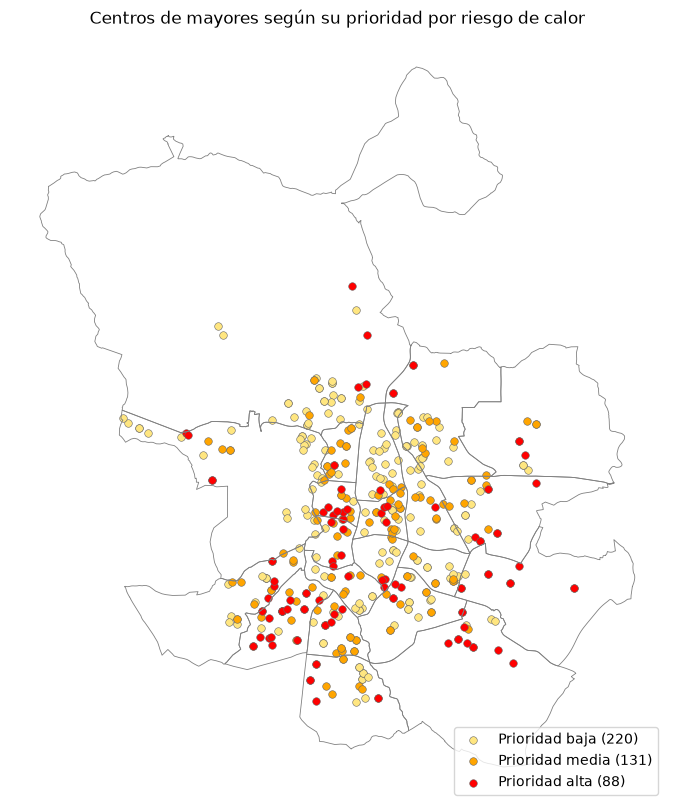

In [39]:
colores_prioridad = {"alta": "red", "media": "orange", "baja": "#ffe680"}

fig, ax = plt.subplots(figsize=(10, 10))
distritos.boundary.plot(ax=ax, color="grey", linewidth=0.6)
for prioridad in ["baja", "media", "alta"]:
    grupo = centros[centros["prioridad"] == prioridad]
    grupo.plot(ax=ax, color=colores_prioridad[prioridad], markersize=30, edgecolor="dimgrey",
               linewidth=0.4, label=f"Prioridad {prioridad} ({len(grupo)})")
ax.set_title("Centros de mayores según su prioridad por riesgo de calor")
ax.legend(loc="lower right")
ax.set_axis_off()
plt.show()

**Observación:** los centros de prioridad alta se concentran en el sur y el sureste de la ciudad, como en el índice de riesgo.

- 7.2. Temperatura de los hexágonos urbanos hoy y en el potencial máximo (plantando +20 de copa en los 1.119 hexágonos del entorno de los centros)

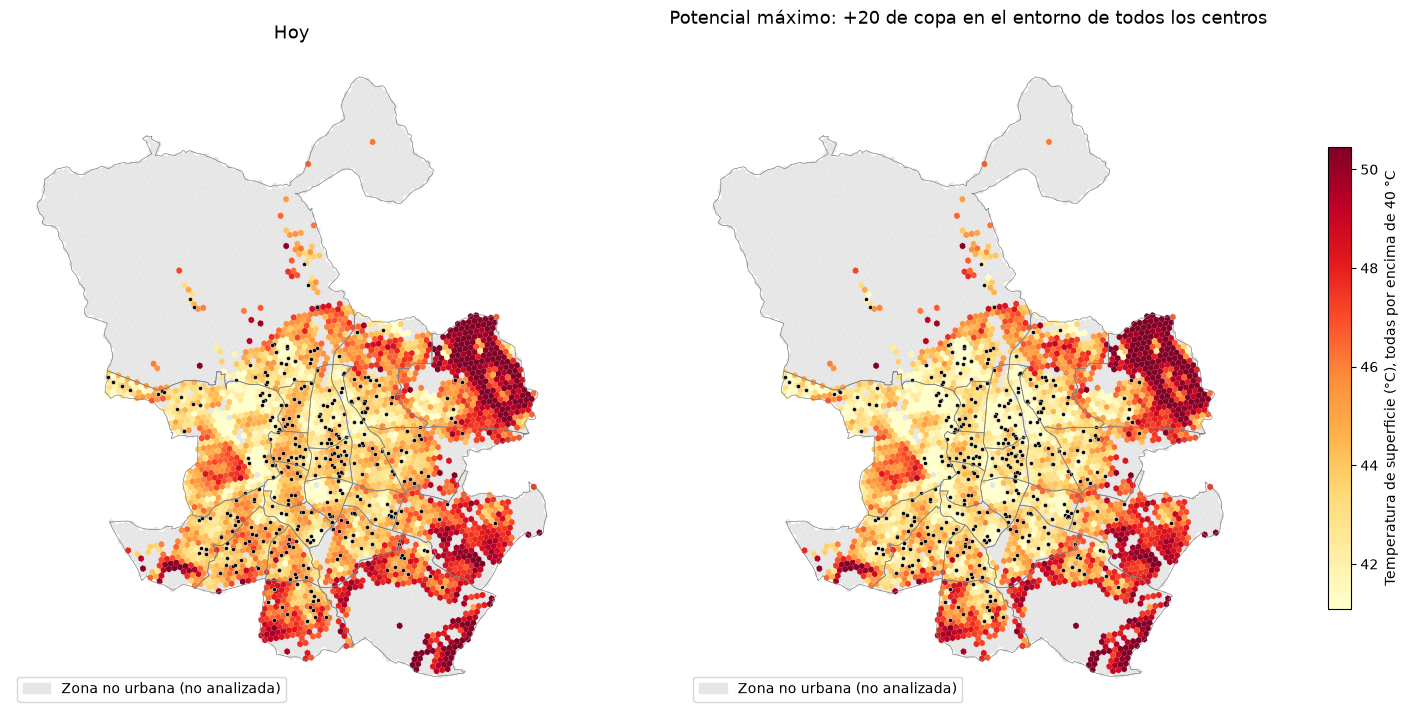

Temperatura media del entorno de los centros hoy: 43.9 °C
Temperatura media en el potencial máximo: 42.66 °C


In [40]:
mapa = hexagonos[["h3", "lst", "geometry"]].merge(candidatos[["h3", "bajada_ambicioso"]], on="h3", how="left")
mapa["bajada_ambicioso"] = mapa["bajada_ambicioso"].fillna(0)
mapa["lst_potencial"] = mapa["lst"] - mapa["bajada_ambicioso"]

fig, axes = plt.subplots(1, 2, figsize=(20, 10))
columnas_mapa = ["lst", "lst_potencial"]
titulos = ["Hoy", "Potencial máximo: +20 de copa en el entorno de todos los centros"]

for eje, columna, titulo in zip(axes, columnas_mapa, titulos):
    hexagonos_todos[~hexagonos_todos["urbano"]].plot(ax=eje, color="#e6e6e6")
    mapa.plot(ax=eje, column=columna, cmap="YlOrRd", vmin=lst_p5, vmax=lst_p95)
    distritos.boundary.plot(ax=eje, color="grey", linewidth=0.5)
    centros.plot(ax=eje, color="black", markersize=8, edgecolor="white", linewidth=0.3)
    eje.set_title(titulo, fontsize=13)
    eje.set_axis_off()
    eje.legend(handles=[Patch(color="#e6e6e6", label="Zona no urbana (no analizada)")], loc="lower left")

barra = plt.cm.ScalarMappable(cmap="YlOrRd", norm=plt.Normalize(vmin=lst_p5, vmax=lst_p95))
fig.colorbar(barra, ax=axes, shrink=0.6, label="Temperatura de superficie (°C), todas por encima de 40 °C")
plt.show()

print("Temperatura media del entorno de los centros hoy:", round(mapa.loc[mapa["bajada_ambicioso"] > 0, "lst"].mean(), 2), "°C")
print("Temperatura media en el potencial máximo:", round(mapa.loc[mapa["bajada_ambicioso"] > 0, "lst_potencial"].mean(), 2), "°C")

**Observación:** con +20 de copa en el entorno de todos los centros, su temperatura media bajaría de 43,9 a 42,7 °C. Los rojos más intensos (Barajas y los polígonos del este y del sureste) apenas cambian, porque no están en el entorno de ningún centro.

- elegimos el centro del zoom: comparamos los candidatos

In [41]:
candidatos_zoom = confort[confort["nombre"].str.contains("CASABLANCA  VILLAVERDE|GONZALEZ BUENO", na=False)]
candidatos_zoom[["codigo", "nombre", "tipo_centro", "prioridad", "pct_confort_hoy", "pct_confort_bajo",
                 "pct_confort_moderado", "pct_confort_ambicioso"]]

,codigo,nombre,tipo_centro,prioridad,pct_confort_hoy,pct_confort_bajo,pct_confort_moderado,pct_confort_ambicioso
10,C1169,"DOCTOR GONZALEZ BUENO, RESIDENCIA DE PERSONAS ...",residencia,alta,47.6,48.7,48.7,50.3
79,C7298,RESIDENCIA DE MAYORES CASABLANCA VILLAVERDE,residencia,alta,51.1,55.7,58.1,59.3
82,C7629,CENTRO DE DIA CASABLANCA VILLAVERDE,centro de día,media,51.1,55.7,58.1,59.3


**Observación:** Casablanca Villaverde gana más confort que Doctor González Bueno (de 51,1 % a 59,3 %, frente a 47,6 % a 50,3 %), así que se elige para el zoom.

- 7.3. Zoom a la Residencia Casablanca Villaverde (y su centro de día, en el mismo edificio): calles, isócrona normal y confortable en cada fase

Edificios en la zona: 96


c:\Users\Usuario\anaconda3\Lib\site-packages\geopandas\plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_dataframe(data, *args, **kwargs)


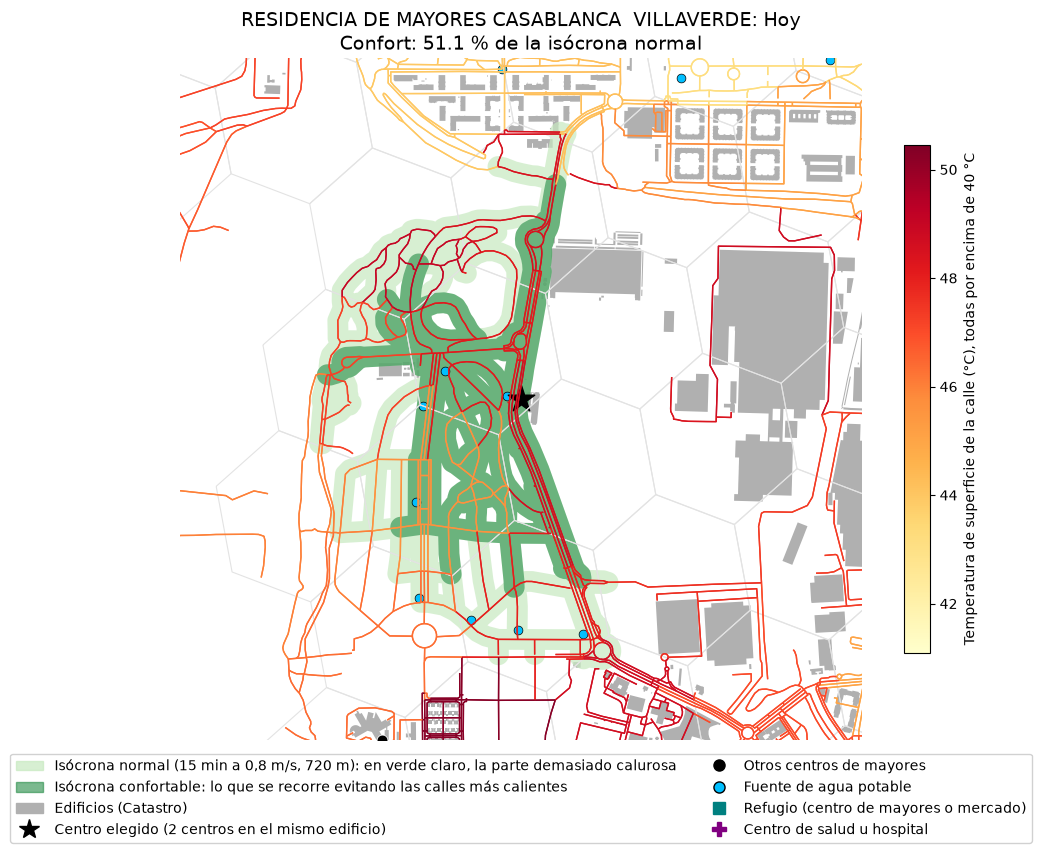

c:\Users\Usuario\anaconda3\Lib\site-packages\geopandas\plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_dataframe(data, *args, **kwargs)


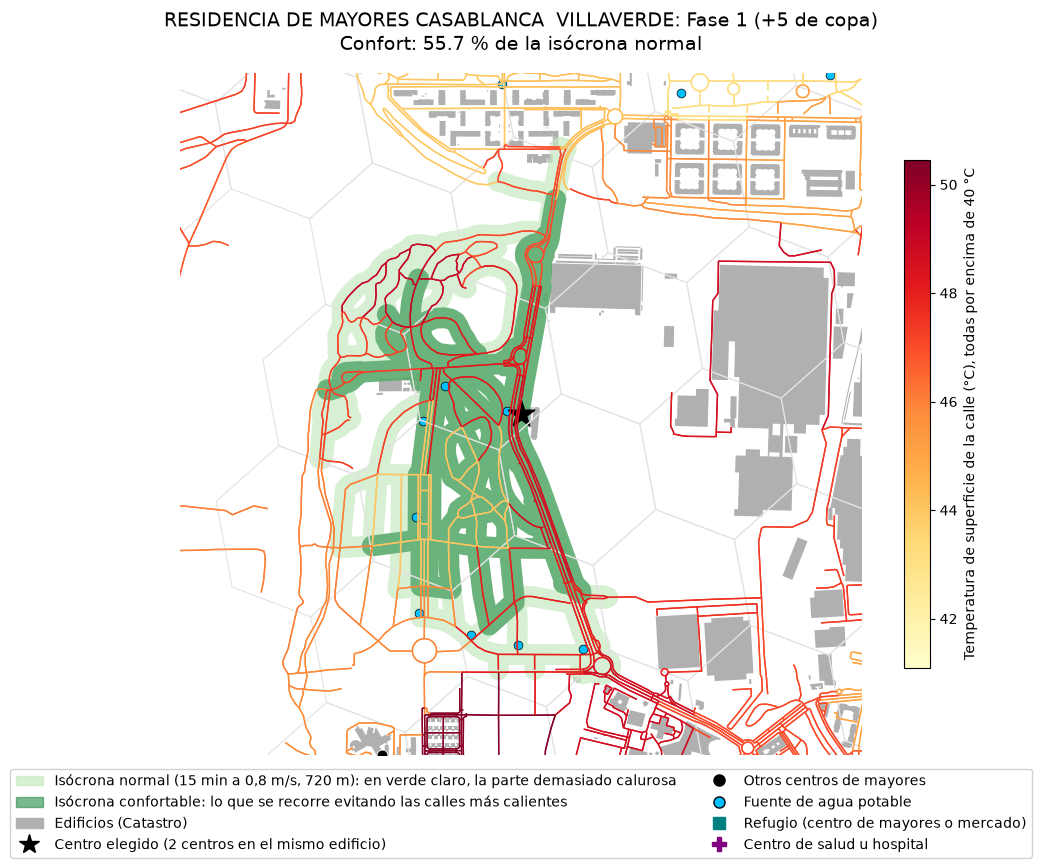

c:\Users\Usuario\anaconda3\Lib\site-packages\geopandas\plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_dataframe(data, *args, **kwargs)


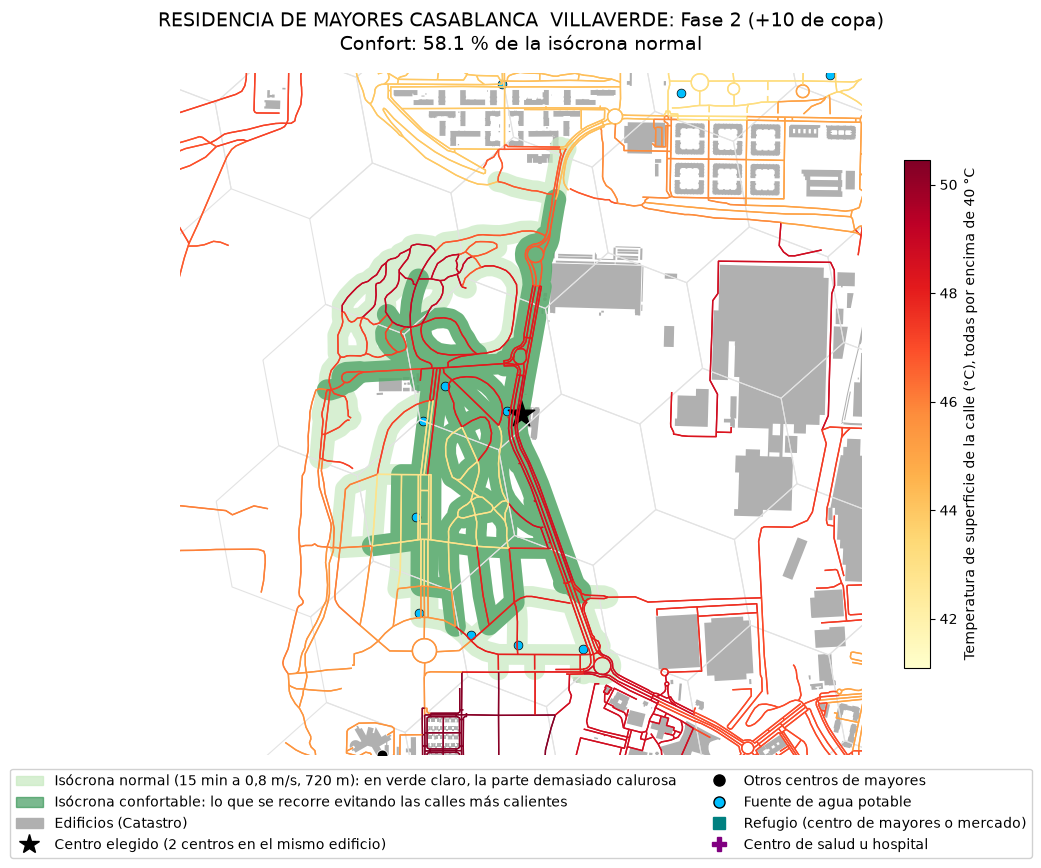

c:\Users\Usuario\anaconda3\Lib\site-packages\geopandas\plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_dataframe(data, *args, **kwargs)


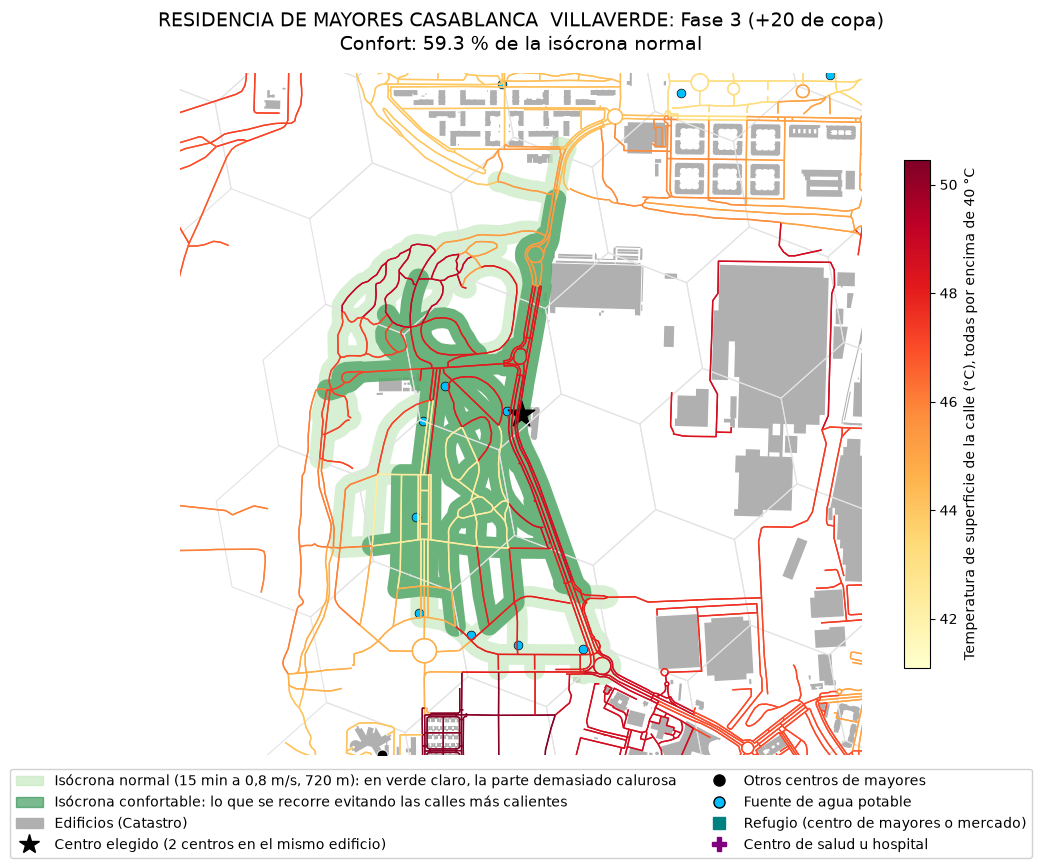

In [44]:
CODIGO_ZOOM = "C7298"
titulos_fases = {"hoy": "Hoy", "bajo": "Fase 1 (+5 de copa)", "moderado": "Fase 2 (+10 de copa)", "ambicioso": "Fase 3 (+20 de copa)"}

isocrona_normal = isocronas_normales[isocronas_normales["codigo"] == CODIGO_ZOOM]
punto_centro = centros[centros["codigo"] == CODIGO_ZOOM]
nombre_centro = punto_centro["nombre"].iloc[0]
RADIO_ZOOM = DISTANCIA_MAXIMA + 100
x_centro = punto_centro.geometry.iloc[0].x
y_centro = punto_centro.geometry.iloc[0].y
xmin, xmax = x_centro - RADIO_ZOOM, x_centro + RADIO_ZOOM
ymin, ymax = y_centro - RADIO_ZOOM, y_centro + RADIO_ZOOM

tramos_zona = tramos.cx[xmin:xmax, ymin:ymax].copy()
hexagonos_zona = hexagonos_todos.cx[xmin:xmax, ymin:ymax]
edificios_zona = gpd.read_file(RUTA_RAW + "dato6/catastro_edificios.gpkg", bbox=(xmin, ymin, xmax, ymax))
print("Edificios en la zona:", len(edificios_zona))
barra = plt.cm.ScalarMappable(cmap="YlOrRd", norm=plt.Normalize(vmin=lst_p5, vmax=lst_p95))
fuentes_zona = gpd.read_file(RUTA_CLEAN + "servicios_fuentes.gpkg").cx[xmin:xmax, ymin:ymax]
salud_zona = gpd.read_file(RUTA_CLEAN + "servicios_salud.gpkg").cx[xmin:xmax, ymin:ymax]
refugios_zona = gpd.read_file(RUTA_CLEAN + "servicios_refugios.gpkg").cx[xmin:xmax, ymin:ymax]
otros_centros = centros[centros["codigo"] != CODIGO_ZOOM].cx[xmin:xmax, ymin:ymax]

centros_mismo_edificio = centros[centros.distance(punto_centro.geometry.iloc[0]) < 10]
if len(centros_mismo_edificio) > 1:
    texto_centro = f"Centro elegido ({len(centros_mismo_edificio)} centros en el mismo edificio)"
else:
    texto_centro = "Centro elegido"

for fase in fases:
    if fase == "hoy":
        tramos_zona["lst_fase"] = tramos_zona["lst"]
    else:
        tramos_zona["lst_fase"] = tramos_zona["lst"] - tramos_zona[f"plan_{fase}"]

    isocrona_fase = isocronas_plan[(isocronas_plan["codigo"] == CODIGO_ZOOM) & (isocronas_plan["fase"] == fase)]

    fig, eje = plt.subplots(figsize=(11, 11))
    hexagonos_zona.boundary.plot(ax=eje, color="#e3e3e3", linewidth=0.8)
    edificios_zona.plot(ax=eje, color="#b0b0b0", edgecolor="none")
    tramos_zona.plot(ax=eje, column="lst_fase", cmap="YlOrRd", vmin=lst_p5, vmax=lst_p95, linewidth=1)
    isocrona_normal.plot(ax=eje, color="#c7e9c0", alpha=0.7)
    isocrona_fase.plot(ax=eje, color="#238b45", alpha=0.6)
    fuentes_zona.plot(ax=eje, color="deepskyblue", marker="o", markersize=40, edgecolor="black", linewidth=0.5)
    salud_zona.plot(ax=eje, color="purple", marker="P", markersize=150, edgecolor="white", linewidth=0.5)
    refugios_zona.plot(ax=eje, color="teal", marker="s", markersize=100, edgecolor="white", linewidth=0.5)
    otros_centros.plot(ax=eje, color="black", marker="o", markersize=60, edgecolor="white", linewidth=0.5)
    punto_centro.plot(ax=eje, color="black", marker="*", markersize=400)

    eje.set_title(f"{nombre_centro}: {titulos_fases[fase]}\nConfort: {isocrona_fase['pct_confort'].iloc[0]} % de la isócrona normal",
                  fontsize=14)
    eje.set_xlim(xmin, xmax)
    eje.set_ylim(ymin, ymax)
    eje.set_axis_off()
    leyenda = [
        Patch(color="#c7e9c0", alpha=0.7, label="Isócrona normal (15 min a 0,8 m/s, 720 m): en verde claro, la parte demasiado calurosa"),
        Patch(color="#238b45", alpha=0.6, label="Isócrona confortable: lo que se recorre evitando las calles más calientes"),
        Patch(color="#b0b0b0", label="Edificios (Catastro)"),
        Line2D([0], [0], marker="*", color="black", linestyle="", markersize=15, label=texto_centro),
        Line2D([0], [0], marker="o", color="black", linestyle="", markersize=8, label="Otros centros de mayores"),
        Line2D([0], [0], marker="o", color="deepskyblue", markeredgecolor="black", linestyle="", markersize=8, label="Fuente de agua potable"),
        Line2D([0], [0], marker="s", color="teal", linestyle="", markersize=9, label="Refugio (centro de mayores o mercado)"),
        Line2D([0], [0], marker="P", color="purple", linestyle="", markersize=10, label="Centro de salud u hospital")
    ]
    eje.legend(handles=leyenda, loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=2, fontsize=10, framealpha=0.9)
    fig.colorbar(barra, ax=eje, shrink=0.6, label="Temperatura de superficie de la calle (°C), todas por encima de 40 °C")
    plt.show()

**Observación del zoom:** la Residencia y el Centro de Día Casablanca Villaverde, en el mismo edificio, están junto a una autovía y rodeados de calles muy calientes. Hoy solo pueden recorrer con comodidad el 51 % de su entorno de 15 minutos, que tiene fuentes pero ningún refugio ni centro de salud.

**Observación de la fase 3:** con +20 puntos de copa, las calles del suroeste del centro pasan de muy calientes a menos calientes, y el área que se puede recorrer con comodidad crece del 51,1 % al 59,3 % del entorno. La autovía que pasa junto al centro sigue siendo la barrera más caliente.

- 7.4. Cifra de cierre

In [43]:
tipos_asistenciales = ["residencia", "centro de día", "vivienda tutelada"]
centros_plan = indice[indice["codigo"].isin(codigos_mejoran)]
n_alta_total = (indice["prioridad"] == "alta").sum()

print("Hexágonos intervenidos:", PRESUPUESTO)
print("Calles intervenidas:", round((tramos["plan_moderado"] > 0).mean() * 100, 1), "% de la red peatonal")
print("Centros beneficiados:", len(centros_plan), "- de prioridad alta:", (centros_plan["prioridad"] == "alta").sum(), "de", n_alta_total)
print("Plazas en residencias, centros de día y viviendas:", int(centros_plan.loc[centros_plan["tipo_centro"].isin(tipos_asistenciales), "plazas"].sum()))
print("Usuarios de centros de mayores:", int(centros_plan.loc[centros_plan["tipo_centro"] == "centro de mayores", "plazas"].sum()))
print("Veces mejor que elegir al azar:", round(curva.loc[curva["hexagonos"] == PRESUPUESTO, "veces_mejor"].iloc[0], 1))
print("\nBajada media en los hexágonos donde se planta (°C):")
print(candidatos.loc[candidatos["elegido"], columnas_plan].mean().round(2))
print("\nPuntos de confort que ganan los centros de prioridad alta:")
print(confort.loc[confort["prioridad"] == "alta", columnas_gana].mean().round(1))

Hexágonos intervenidos: 50
Calles intervenidas: 1.8 % de la red peatonal
Centros beneficiados: 104 - de prioridad alta: 53 de 88
Plazas en residencias, centros de día y viviendas: 9111
Usuarios de centros de mayores: 6537
Veces mejor que elegir al azar: 4.8

Bajada media en los hexágonos donde se planta (°C):
plan_bajo         0.70
plan_moderado     1.02
plan_ambicioso    1.75
dtype: float64

Puntos de confort que ganan los centros de prioridad alta:
gana_bajo         0.8
gana_moderado     1.4
gana_ambicioso    2.9
dtype: float64


**Conclusión:** el modelo no solo predice la temperatura, sino que decide dónde actuar. En el 83 % de los centros de prioridad alta, lo que más calienta su entorno es la falta de vegetación, así que plantar árboles es la medida principal. Con un presupuesto de 50 hexágonos, el optimizador elige los lugares donde plantar enfría más a los centros con más riesgo: llega a 53 de los 88 centros prioritarios, con 4,8 veces más beneficio que elegir al azar. El efecto es local: las calles intervenidas bajan hasta 3,4 °C y el área cómoda de algunos centros crece hasta 8,5 puntos, pero barreras como las autovías siguen sin poder corregirse con arbolado.

- comprobamos que el script scrips/priorizacion.py da exactamente el mismo resultado que el notebook

In [46]:
from priorizacion import calcular_priorizacion

resultados_script = calcular_priorizacion()
nombres = ["Diagnóstico", "Candidatos", "Curva", "Antes y después", "Confort", "Isócronas del plan"]
resultados_notebook = [diagnostico, candidatos, curva, antes_despues, confort, isocronas_plan]

for nombre, notebook, script in zip(nombres, resultados_notebook, resultados_script):
    print(f"{nombre}:", notebook.equals(script))

Diagnóstico: True
Candidatos: True
Curva: True
Antes y después: True
Confort: True
Isócronas del plan: True


## 8. Archivos para la app

**Decisión:** la app se publica en Streamlit Cloud, que lee el repositorio de GitHub, donde no está la carpeta raw/ (archivos de más de 100 MB). Por eso se guardan en clean/ solo los tramos de calle y los edificios a menos de 820 m de algún centro, que es la zona que muestra el zoom de la app.

- guardamos la curva del optimizador

In [49]:
curva.to_csv(RUTA_CLEAN + "priorizacion_curva.csv", index=False)

- zona de la app: 820 m alrededor de cada centro, y tramos de calle dentro de esa zona con su temperatura y su bajada en cada fase

In [52]:
zona_app = centros.buffer(DISTANCIA_MAXIMA + 100).union_all()

posiciones = tramos.sindex.query(zona_app, predicate="intersects")
tramos_app = tramos.iloc[posiciones]
un_sentido = tramos_app.index.get_level_values("u") < tramos_app.index.get_level_values("v")
tramos_app = tramos_app[un_sentido][["lst"] + columnas_plan + ["geometry"]].reset_index(drop=True)
tramos_app.to_parquet(RUTA_CLEAN + "app_tramos.parquet")

print("Tramos en la zona de la app:", len(tramos_app))
print("Tamaño del archivo:", round(os.path.getsize(RUTA_CLEAN + "app_tramos.parquet") / 1_000_000, 1), "MB")

Tramos en la zona de la app: 216149
Tamaño del archivo: 8.2 MB


- edificios del Catastro dentro de la zona de la app, solo con su forma

In [53]:
edificios_app = gpd.read_file(RUTA_RAW + "dato6/catastro_edificios.gpkg", columns=["localId"], mask=zona_app)
edificios_app = edificios_app[["geometry"]]
edificios_app["geometry"] = edificios_app.simplify(1)
edificios_app.to_parquet(RUTA_CLEAN + "app_edificios.parquet")

print("Edificios en la zona de la app:", len(edificios_app))
print("Tamaño del archivo:", round(os.path.getsize(RUTA_CLEAN + "app_edificios.parquet") / 1_000_000, 1), "MB")

Edificios en la zona de la app: 116894
Tamaño del archivo: 14.1 MB


**Observación:** 116.894 edificios en la zona de la app, en un archivo de 14,1 MB; los dos archivos caben en GitHub (límite de 100 MB por archivo).

- guardamos los límites de los distritos para los mapas de la app

In [54]:
distritos.to_file(RUTA_CLEAN + "app_distritos.gpkg", driver="GPKG")